## Transformer based model

### Data load and explore

In [1]:
import pandas as pd

data = pd.read_csv('email.csv')
df = pd.DataFrame(data)

df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
print(df.shape)
print(df.info())
print("Null: ",df.isnull().sum())
print("Duplicates: ",df.duplicated().sum())

(5573, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5573 entries, 0 to 5572
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5573 non-null   object
 1   Message   5573 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
Null:  Category    0
Message     0
dtype: int64
Duplicates:  415


### Preprocessing

In [3]:
df.drop_duplicates(inplace=True)
print(df.shape)

(5158, 2)


In [4]:
print(df["Category"].value_counts(normalize=True) * 100)

Category
ham               87.553315
spam              12.427297
{"mode":"full"     0.019387
Name: proportion, dtype: float64


In [5]:
df['Message'] = df['Message'].astype(str).str.strip().str.lower()
df = df[df['Message'] != '']
print(df.shape)
df.head()

(5158, 2)


,Category,Message
0,ham,"go until jurong point, crazy.. available only ..."
1,ham,ok lar... joking wif u oni...
2,spam,free entry in 2 a wkly comp to win fa cup fina...
3,ham,u dun say so early hor... u c already then say...
4,ham,"nah i don't think he goes to usf, he lives aro..."


In [6]:
df['Category'] = df['Category'].map({'spam':1,'ham':0})  
df.head()

,Category,Message
0,0.0,"go until jurong point, crazy.. available only ..."
1,0.0,ok lar... joking wif u oni...
2,1.0,free entry in 2 a wkly comp to win fa cup fina...
3,0.0,u dun say so early hor... u c already then say...
4,0.0,"nah i don't think he goes to usf, he lives aro..."


In [7]:
print(df['Category'].isnull().sum())
df.dropna(inplace=True)
df.head()

1


,Category,Message
0,0.0,"go until jurong point, crazy.. available only ..."
1,0.0,ok lar... joking wif u oni...
2,1.0,free entry in 2 a wkly comp to win fa cup fina...
3,0.0,u dun say so early hor... u c already then say...
4,0.0,"nah i don't think he goes to usf, he lives aro..."


### Train-test split

In [8]:
from sklearn.model_selection import train_test_split

X = df['Message']
y = df['Category']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4125
Testing samples: 1032


In [9]:
print((y_train.value_counts(normalize=True) * 100).round(2))
print((y_test.value_counts(normalize=True) * 100).round(2))


Category
0.0    87.56
1.0    12.44
Name: proportion, dtype: float64
Category
0.0    87.6
1.0    12.4
Name: proportion, dtype: float64


### TF-IDF Vectorization

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (4125, 5000)
Testing shape: (1032, 5000)


In [11]:
%pip install transformers torch

Note: you may need to restart the kernel to use updated packages.


### Model import and tokenization

In [12]:
import torch
import numpy as np

y_train_num = y_train.astype(int)
y_test_num = y_test.astype(int)

In [13]:
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train.fillna("").astype(str),
    y_train_num,
    test_size=0.1,
    random_state=42,
    stratify=y_train_num
)

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

print("Training:", len(X_tr))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

C:\Users\anshu\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\anshu\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\anshu\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an a

Training: 3712
Validation: 413
Testing: 1032


In [14]:
train_tokens = tokenizer(
    X_tr.tolist(),
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

val_tokens = tokenizer(
    X_val.tolist(),
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

test_tokens = tokenizer(
    X_test.fillna("").astype(str).tolist(),
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Tokenized training shape:", train_tokens["input_ids"].shape)

Tokenized training shape: torch.Size([3712, 128])


In [15]:
from torch.utils.data import Dataset, DataLoader

class EmailDataset(Dataset):
    def __init__(self, tokens, labels):
        self.tokens = tokens
        self.labels = torch.tensor(
            np.asarray(labels, dtype=np.int64)
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            key: value[index]
            for key, value in self.tokens.items()
        }
        item["labels"] = self.labels[index]
        return item


train_dataset = EmailDataset(train_tokens, y_tr)
val_dataset = EmailDataset(val_tokens, y_val)
test_dataset = EmailDataset(test_tokens, y_test_num)

train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=8, shuffle=False
)

In [16]:
from transformers import AutoModelForSequenceClassification

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

model.to(device)

print("Device:", device)

C:\Users\anshu\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\anshu\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 788.02it/s]
[transformers] DistilBertForSequenceClassification LOAD

Device: cpu


### Model training

In [17]:
import time
import matplotlib.pyplot as plt

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5
)

epochs = 2
train_losses = []
val_losses = []

start_time = time.time()

for epoch in range(epochs):

    # Training
    model.train()
    total_train_loss = 0

    for batch in train_loader:
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        output = model(**batch)
        loss = output.loss

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation
    model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for batch in val_loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            output = model(**batch)
            total_val_loss += output.loss.item()

    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Validation Loss: {avg_val_loss:.4f}"
    )

transformer_training_time = time.time() - start_time

print("Training time:", round(transformer_training_time, 2), "seconds")

Epoch 1/2 | Train Loss: 0.0747 | Validation Loss: 0.0143
Epoch 2/2 | Train Loss: 0.0229 | Validation Loss: 0.0031
Training time: 2932.08 seconds


 ### Model evaluation and visualization

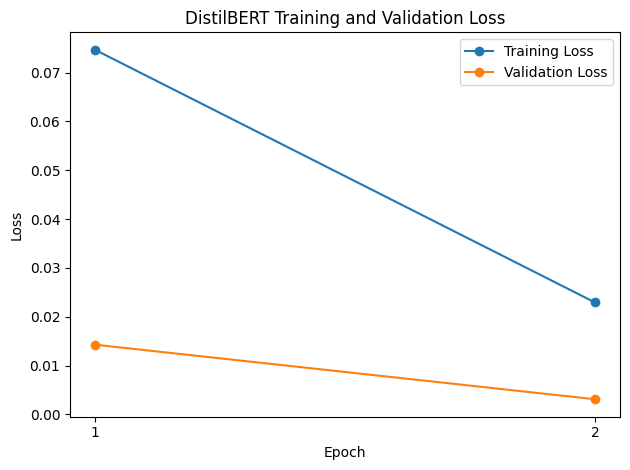

In [18]:
plt.plot(train_losses, marker="o", label="Training Loss")
plt.plot(val_losses, marker="o", label="Validation Loss")

plt.title("DistilBERT Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(epochs), range(1, epochs + 1))
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

model.eval()
y_pred_bert = []

with torch.no_grad():
    for batch in test_loader:
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        output = model(**batch)
        predictions = torch.argmax(output.logits, dim=1)

        y_pred_bert.extend(predictions.cpu().numpy())

y_true_bert = np.asarray(y_test_num)

bert_results = {
    "Model": "DistilBERT",
    "Accuracy": accuracy_score(y_true_bert, y_pred_bert),
    "Precision": precision_score(
        y_true_bert, y_pred_bert, zero_division=0
    ),
    "Recall": recall_score(
        y_true_bert, y_pred_bert, zero_division=0
    ),
    "F1-score": f1_score(
        y_true_bert, y_pred_bert, zero_division=0
    ),
    "Training Time (s)": round(transformer_training_time, 2)
}

print(pd.DataFrame([bert_results]).round(4))

        Model  Accuracy  Precision  Recall  F1-score  Training Time (s)
0  DistilBERT    0.9884     0.9915  0.9141    0.9512            2932.08


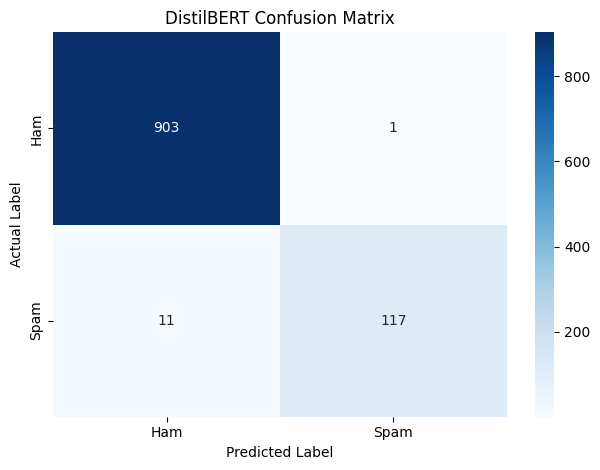

In [21]:
import seaborn as sns
cm = confusion_matrix(
    y_true_bert, y_pred_bert, labels=[0, 1]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()